# Theme Alpha Q6 Bear Defense Benchmark Completion Practice

Q6 completes missing bear-market benchmarks and tests simple core defense rules.

Main questions:

1. Is expanded LowVolTrend better than simple expanded equal weight or expanded RiskParity?
2. Can a simple defense rule for the core sleeve reduce bear-market damage without destroying upside?

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q6-bear-defense-benchmark-completion")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2020-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0

REBALANCE_DAYS = 10
REBALANCE_ANCHOR = "2020-01-02"

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

CORE_ASSETS = (CSI300, NASDAQ, GOLD)
ORIGINAL_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD)
EXPANDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(CORE_ASSETS + EXPANDED_THEME))
SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50
DEFENSE_WINDOWS = {"Def120": 120, "Def200": 200, "Def210": 210}

WINDOWS = {
    "2021_to_date": ("2021-01-01", None),
    "2021_2022_bear": ("2021-02-18", "2022-10-31"),
    "2022_full": ("2022-01-01", "2022-12-31"),
    "2023_full": ("2023-01-01", "2023-12-31"),
    "2024_full": ("2024-01-01", "2024-12-31"),
    "2025_to_date": ("2025-01-01", None),
    "2026_ytd": ("2026-01-01", None),
}

print(f"Output dir: {OUTPUT_DIR}")
print(f"End date request: {END}")

Output dir: outputs/theme-alpha-q6-bear-defense-benchmark-completion
End date request: 2026-06-24


## Data

Daily adjusted ETF prices are downloaded from yfinance. The calendar is the union of all assets and missing values are forward-filled after listing. A strategy excludes assets that do not yet have enough history at a rebalance date.

In [2]:
def download_close(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    if isinstance(df.columns, pd.MultiIndex):
        df = df.droplevel(1, axis=1)
    col = "Close" if "Close" in df.columns else "Adj Close"
    return df[col].rename(symbol)

raw_close = [download_close(symbol) for symbol in ALL_SYMBOLS]
close_raw = pd.concat(raw_close, axis=1).sort_index()
availability = pd.DataFrame([
    {
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "first_date": close_raw[sym].dropna().index.min().date(),
        "last_date": close_raw[sym].dropna().index.max().date(),
        "rows": int(close_raw[sym].dropna().shape[0]),
    }
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

close = close_raw.ffill()
returns = close.pct_change(fill_method=None)

,symbol,name,first_date,last_date,rows
0,510300.SS,沪深300ETF,2020-01-02,2026-06-23,1565
1,513100.SS,纳指100ETF,2020-01-02,2026-06-23,1566
2,518880.SS,黄金ETF,2020-01-02,2026-06-23,1565
3,512400.SS,有色金属ETF,2020-01-02,2026-06-23,1565
4,159995.SZ,芯片ETF,2020-01-20,2026-06-23,1547
5,515880.SS,通信ETF,2020-01-02,2026-06-23,1565
6,510880.SS,红利ETF,2020-01-02,2026-06-23,1565
7,159930.SZ,能源ETF,2020-01-02,2026-06-23,1543
8,512880.SS,证券ETF,2020-01-02,2026-06-23,1565
9,513180.SS,恒生科技ETF,2021-05-18,2026-06-23,1233


## Strategy Helpers

In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def rebalance_dates(index):
    idx = pd.DatetimeIndex(index)
    start = idx.searchsorted(pd.Timestamp(REBALANCE_ANCHOR))
    return set(pd.DatetimeIndex(idx[start::REBALANCE_DAYS]))


def enough_history(sym, loc, window):
    if loc < window:
        return False
    hist = close[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def enough_return_history(sym, loc, window):
    if loc < window:
        return False
    hist = returns[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def eligible_for_weighting(universe, loc, price_window=1, return_window=RP_VOL_WINDOW):
    out = []
    for sym in universe:
        if price_window and not enough_history(sym, loc, price_window):
            continue
        if return_window and not enough_return_history(sym, loc, return_window):
            continue
        out.append(sym)
    return out


def equal_weight(date, eligible, universe):
    loc = close.index.get_loc(date)
    eligible = [sym for sym in eligible if sym in universe and enough_history(sym, loc, 1)]
    if not eligible:
        return normalize_weights({}, universe)
    w = 1.0 / len(eligible)
    return normalize_weights({sym: w for sym in eligible}, universe)


def risk_parity_weight(date, eligible, universe, cap=None):
    loc = close.index.get_loc(date)
    eligible = [sym for sym in eligible if sym in universe and enough_return_history(sym, loc, RP_VOL_WINDOW)]
    if not eligible:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1:loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def low_vol_trend_selector(universe):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(MA_WINDOW, MOM_WINDOW, VOL_WINDOW)
        if loc < warmup:
            return []
        valid = []
        for sym in universe:
            if not enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)):
                continue
            if not enough_return_history(sym, loc, VOL_WINDOW):
                continue
            valid.append(sym)
        if not valid:
            return []
        price = close.iloc[loc][valid]
        ma = close.iloc[loc - MA_WINDOW + 1:loc + 1][valid].mean()
        mom = price / close.iloc[loc - MOM_WINDOW][valid] - 1.0
        vols = returns.iloc[loc - VOL_WINDOW + 1:loc + 1][valid].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(TOP_N).index.tolist()
    return select


def all_assets(universe):
    return lambda _date: list(universe)


def available_assets(universe, min_price_window=1, min_return_window=0):
    def select(date):
        loc = close.index.get_loc(date)
        return eligible_for_weighting(universe, loc, min_price_window, min_return_window)
    return select


def build_weights(universe, selector, allocator):
    rdates = rebalance_dates(close.index)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in rdates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def defend_core_weights(weights, ma_window, destination):
    rdates = rebalance_dates(close.index)
    rows = []
    last = normalize_weights({}, CORE_ASSETS)
    for date in close.index:
        if date in rdates:
            loc = close.index.get_loc(date)
            base = weights.loc[date, list(CORE_ASSETS) + ["CASH"]].copy()
            for sym in (CSI300, NASDAQ):
                risk_on = enough_history(sym, loc, ma_window) and close.at[date, sym] > close[sym].iloc[loc - ma_window + 1:loc + 1].mean()
                if not risk_on:
                    moved = base[sym]
                    base[sym] = 0.0
                    if destination == "cash":
                        base["CASH"] += moved
                    elif destination == "gold":
                        base[GOLD] += moved
                    else:
                        raise ValueError(destination)
            last = normalize_weights(base.to_dict(), CORE_ASSETS)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    return out[list(CORE_ASSETS) + ["CASH"]]


def expand_weights(weights, all_assets):
    out = pd.DataFrame(0.0, index=weights.index, columns=list(all_assets) + ["CASH"])
    for col in weights.columns:
        if col in out.columns:
            out[col] = weights[col]
    return out


def combine_weights(name, sleeves):
    out = pd.DataFrame(0.0, index=close.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for allocation, weights in sleeves:
        ew = expand_weights(weights, ALL_SYMBOLS)
        out += allocation * ew.reindex(close.index).ffill().fillna(0.0)
    total = out[list(ALL_SYMBOLS)].sum(axis=1) + out["CASH"]
    out = out.div(total.replace(0, np.nan), axis=0).fillna(0.0)
    return out


def turnover_from_weights(signal_weights):
    actual = signal_weights[list(ALL_SYMBOLS) + ["CASH"]].shift(1).fillna(0.0)
    return 0.5 * actual.diff().abs().sum(axis=1).fillna(actual.abs().sum(axis=1))


def backtest_combined(name, signal_weights, cost_bps=0.0):
    asset_weights = signal_weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(ALL_SYMBOLS)]).sum(axis=1, min_count=1).fillna(0.0)
    turnover = turnover_from_weights(signal_weights)
    net = gross - turnover * (cost_bps / 10000.0)
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {"name": name, "weights": signal_weights, "returns": net, "gross_returns": gross, "turnover": turnover, "nav": nav.rename(name), "cost_bps": cost_bps}


def fixed_weight_portfolio(name, weights):
    w = pd.DataFrame(0.0, index=close.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for sym, val in weights.items():
        w[sym] = val
    w["CASH"] = max(0.0, 1.0 - sum(weights.values()))
    return backtest_combined(name, w)

## Build Portfolios

This section separates simple benchmarks from LVT and core-defense variants.

In [4]:
core_rp_w = build_weights(CORE_ASSETS, all_assets(CORE_ASSETS), lambda d, e: risk_parity_weight(d, e, CORE_ASSETS, None))
core_ew_w = build_weights(CORE_ASSETS, available_assets(CORE_ASSETS, 1, 0), lambda d, e: equal_weight(d, e, CORE_ASSETS))

orig_ew_w = build_weights(ORIGINAL_THEME, available_assets(ORIGINAL_THEME, 1, 0), lambda d, e: equal_weight(d, e, ORIGINAL_THEME))
orig_rp_w = build_weights(ORIGINAL_THEME, available_assets(ORIGINAL_THEME, 1, RP_VOL_WINDOW), lambda d, e: risk_parity_weight(d, e, ORIGINAL_THEME, None))

expanded_ew_w = build_weights(EXPANDED_THEME, available_assets(EXPANDED_THEME, 1, 0), lambda d, e: equal_weight(d, e, EXPANDED_THEME))
expanded_rp_w = build_weights(EXPANDED_THEME, available_assets(EXPANDED_THEME, 1, RP_VOL_WINDOW), lambda d, e: risk_parity_weight(d, e, EXPANDED_THEME, None))
expanded_lvt_w = build_weights(EXPANDED_THEME, low_vol_trend_selector(EXPANDED_THEME), lambda d, e: risk_parity_weight(d, e, EXPANDED_THEME, CAP))

weights_map = {
    "CoreRP_100": combine_weights("CoreRP_100", [(1.0, core_rp_w)]),
    "CoreEW_100": combine_weights("CoreEW_100", [(1.0, core_ew_w)]),
    "OriginalThemeEW_100": combine_weights("OriginalThemeEW_100", [(1.0, orig_ew_w)]),
    "OriginalThemeRP_100": combine_weights("OriginalThemeRP_100", [(1.0, orig_rp_w)]),
    "ExpandedEW_100": combine_weights("ExpandedEW_100", [(1.0, expanded_ew_w)]),
    "ExpandedRP_100": combine_weights("ExpandedRP_100", [(1.0, expanded_rp_w)]),
    "ExpandedLVT_100": combine_weights("ExpandedLVT_100", [(1.0, expanded_lvt_w)]),
    "Core80_ExpandedLVT20": combine_weights("Core80_ExpandedLVT20", [(0.80, core_rp_w), (0.20, expanded_lvt_w)]),
}

for label, window in DEFENSE_WINDOWS.items():
    for dest in ("cash", "gold"):
        def_core = defend_core_weights(core_rp_w, window, dest)
        name = f"Core80_ExpandedLVT20_{label}_{dest.title()}"
        weights_map[name] = combine_weights(name, [(0.80, def_core), (0.20, expanded_lvt_w)])

portfolios = {name: backtest_combined(name, weights) for name, weights in weights_map.items()}
benchmarks = {
    "CSI300_100": fixed_weight_portfolio("CSI300_100", {CSI300: 1.0}),
    "NASDAQ_100": fixed_weight_portfolio("NASDAQ_100", {NASDAQ: 1.0}),
    "Gold_100": fixed_weight_portfolio("Gold_100", {GOLD: 1.0}),
    "CSI300_Gold_60_40": fixed_weight_portfolio("CSI300_Gold_60_40", {CSI300: 0.60, GOLD: 0.40}),
}
all_portfolios = {**portfolios, **benchmarks}

latest = []
avg = []
for name, weights in weights_map.items():
    latest.append({"策略": name, **{SYMBOL_NAMES.get(c, c): weights[c].iloc[-1] for c in ALL_SYMBOLS}, "现金": weights["CASH"].iloc[-1]})
    avg.append({"策略": name, **{SYMBOL_NAMES.get(c, c): weights[c].mean() for c in ALL_SYMBOLS}, "现金": weights["CASH"].mean()})
latest_weights = pd.DataFrame(latest)
average_weights = pd.DataFrame(avg)
latest_weights.to_csv(OUTPUT_DIR / "latest_weights.csv", index=False, encoding="utf-8-sig")
average_weights.to_csv(OUTPUT_DIR / "average_weights.csv", index=False, encoding="utf-8-sig")
display(latest_weights.round(4))

,策略,沪深300ETF,纳指100ETF,黄金ETF,有色金属ETF,芯片ETF,通信ETF,红利ETF,能源ETF,证券ETF,恒生科技ETF,医疗ETF,现金
0,CoreRP_100,0.4595,0.2189,0.3216,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0
1,CoreEW_100,0.3333,0.3333,0.3333,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0
2,OriginalThemeEW_100,0.0000,0.2000,0.2000,0.2000,0.2000,0.2000,0.0000,0.0000,0.0000,0.0000,0.000,0.0
3,OriginalThemeRP_100,0.0000,0.2137,0.3140,0.1883,0.1410,0.1430,0.0000,0.0000,0.0000,0.0000,0.000,0.0
4,ExpandedEW_100,0.0000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.1000,0.100,0.0
5,ExpandedRP_100,0.0000,0.0689,0.1013,0.0608,0.0455,0.0462,0.1732,0.0977,0.1236,0.1038,0.179,0.0
6,ExpandedLVT_100,0.0000,0.4293,0.0000,0.0000,0.2832,0.2874,0.0000,0.0000,0.0000,0.0000,0.000,0.0
7,Core80_ExpandedLVT20,0.3676,0.2610,0.2573,0.0000,0.0566,0.0575,0.0000,0.0000,0.0000,0.0000,0.000,0.0
8,Core80_ExpandedLVT20_Def120_Cash,0.3676,0.2610,0.2573,0.0000,0.0566,0.0575,0.0000,0.0000,0.0000,0.0000,0.000,0.0
9,Core80_ExpandedLVT20_Def120_Gold,0.3676,0.2610,0.2573,0.0000,0.0566,0.0575,0.0000,0.0000,0.0000,0.0000,0.000,0.0


## Metrics

In [5]:
def period_slice(series_or_df, start, end):
    obj = series_or_df.loc[pd.Timestamp(start):]
    if end is not None:
        obj = obj.loc[:pd.Timestamp(end)]
    return obj.dropna(how="all") if isinstance(obj, pd.DataFrame) else obj.dropna()


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown_series(nav):
    nav = nav.dropna()
    if nav.empty:
        return nav
    initial_peak = pd.Series([INITIAL_NAV], index=[nav.index[0] - pd.Timedelta(nanoseconds=1)])
    peak = pd.concat([initial_peak, nav]).cummax().iloc[1:]
    return nav / peak - 1.0


def max_drawdown(nav):
    dd = drawdown_series(nav)
    return float(dd.min())


def longest_true_run(mask):
    longest = cur = 0
    for val in mask.astype(bool):
        if val:
            cur += 1
            longest = max(longest, cur)
        else:
            cur = 0
    return int(longest)


def recovery_summary(nav):
    nav = nav.dropna()
    if nav.empty:
        return {"水下时间占比": np.nan, "平均水下": np.nan, "最长水下天数": np.nan, "超过-10%天数": np.nan, "超过-20%天数": np.nan, "平均修复天数": np.nan, "最长修复天数": np.nan, "未修复回撤": np.nan}
    dd = drawdown_series(nav)
    underwater = dd < -1e-12
    durations = []
    start_idx = None
    for i, is_under in enumerate(underwater.values):
        if is_under and start_idx is None:
            start_idx = i
        if (not is_under) and start_idx is not None:
            durations.append(i - start_idx)
            start_idx = None
    unresolved = float(dd.iloc[-1]) if start_idx is not None else 0.0
    completed = [d for d in durations if d > 0]
    return {
        "水下时间占比": float(underwater.mean()),
        "平均水下": float(dd[underwater].mean()) if underwater.any() else 0.0,
        "最长水下天数": longest_true_run(underwater),
        "超过-10%天数": int((dd <= -0.10).sum()),
        "超过-20%天数": int((dd <= -0.20).sum()),
        "平均修复天数": float(np.mean(completed)) if completed else 0.0,
        "最长修复天数": int(max(completed)) if completed else 0,
        "未修复回撤": unresolved,
    }


def metrics_row(name, r, weights=None, turnover=None):
    r = r.dropna()
    if r.empty:
        return {"策略": name}
    nav = nav_from_returns(r)
    total = float((1.0 + r).prod() - 1.0)
    years = max(len(r) / TRADING_DAYS, 1e-12)
    ann = (1.0 + total) ** (1.0 / years) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ann / vol if vol and vol > 0 else np.nan
    downside = r[r < 0].std(ddof=1) * np.sqrt(TRADING_DAYS)
    sortino = ann / downside if downside and downside > 0 else np.nan
    mdd = max_drawdown(nav)
    calmar = ann / abs(mdd) if mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = monthly[monthly > 0]
    losses = monthly[monthly < 0]
    row = {
        "策略": name,
        "累计收益": total,
        "年化收益": ann,
        "年化波动": vol,
        "最大回撤": mdd,
        "夏普": sharpe,
        "索提诺": sortino,
        "卡玛": calmar,
        "月胜率": (monthly > 0).mean(),
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最好月份": monthly.max() if len(monthly) else np.nan,
        "最差月份": monthly.min() if len(monthly) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
    }
    row.update(recovery_summary(nav))
    if turnover is not None:
        t = turnover.reindex(r.index).fillna(0.0)
        row["年化换手"] = t.sum() / years
        row["总换手"] = t.sum()
    if weights is not None:
        w = weights.reindex(r.index).ffill().fillna(0.0)
        row["平均现金"] = w["CASH"].mean()
        row["平均最大单资产权重"] = w[list(ALL_SYMBOLS)].max(axis=1).mean()
        row["当前最大单资产权重"] = w[list(ALL_SYMBOLS)].iloc[-1].max()
    return row


def monthly_diagnostics(name, r):
    m = r.dropna().resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = m[m > 0]
    losses = m[m < 0]
    return {
        "策略": name,
        "月份数": len(m),
        "胜率": (m > 0).mean() if len(m) else np.nan,
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最好月份": m.max() if len(m) else np.nan,
        "最差月份": m.min() if len(m) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
    }


def top_drawdown_events(nav, top_n=5):
    dd = drawdown_series(nav)
    events = []
    in_dd = False
    start = trough = None
    trough_depth = 0.0
    for date, depth in dd.items():
        if depth < -1e-12 and not in_dd:
            in_dd = True
            start = date
            trough = date
            trough_depth = depth
        elif in_dd:
            if depth < trough_depth:
                trough = date
                trough_depth = depth
            if depth >= -1e-12:
                events.append({"start": start, "trough": trough, "recovery": date, "depth": trough_depth, "days": (date - start).days})
                in_dd = False
    if in_dd:
        events.append({"start": start, "trough": trough, "recovery": pd.NaT, "depth": trough_depth, "days": (nav.index[-1] - start).days})
    return pd.DataFrame(events).sort_values("depth").head(top_n) if events else pd.DataFrame(columns=["start", "trough", "recovery", "depth", "days"])

## Evaluate Windows

In [6]:
def evaluate_window(window_name, start, end):
    summary_rows = []
    monthly_rows = []
    recovery_rows = []
    navs = {}
    underwater = {}
    for name, port in all_portfolios.items():
        r = period_slice(port["returns"], start, end)
        w = period_slice(port["weights"], start, end)
        t = period_slice(port["turnover"], start, end)
        nav = nav_from_returns(r)
        summary_rows.append(metrics_row(name, r, w, t))
        monthly_rows.append(monthly_diagnostics(name, r))
        recovery_rows.append({"策略": name, **recovery_summary(nav)})
        navs[name] = nav
        underwater[name] = drawdown_series(nav)
        events = top_drawdown_events(nav)
        events.to_csv(OUTPUT_DIR / f"drawdown_events_{window_name}_{name}.csv", index=False, encoding="utf-8-sig")
    summary = pd.DataFrame(summary_rows).set_index("策略")
    preferred_order = list(portfolios.keys()) + list(benchmarks.keys())
    summary = summary.reindex(preferred_order)
    monthly = pd.DataFrame(monthly_rows).set_index("策略").reindex(preferred_order)
    recovery = pd.DataFrame(recovery_rows).set_index("策略").reindex(preferred_order)
    nav_df = pd.DataFrame(navs)
    uw_df = pd.DataFrame(underwater)
    summary.to_csv(OUTPUT_DIR / f"summary_{window_name}.csv", encoding="utf-8-sig")
    monthly.to_csv(OUTPUT_DIR / f"monthly_diagnostics_{window_name}.csv", encoding="utf-8-sig")
    recovery.to_csv(OUTPUT_DIR / f"underwater_recovery_{window_name}.csv", encoding="utf-8-sig")
    nav_df.to_csv(OUTPUT_DIR / f"nav_{window_name}.csv", encoding="utf-8-sig")
    uw_df.to_csv(OUTPUT_DIR / f"underwater_{window_name}.csv", encoding="utf-8-sig")
    return summary, monthly, recovery, nav_df, uw_df

summary_tables = {}
monthly_tables = {}
recovery_tables = {}
nav_tables = {}
underwater_tables = {}
for window_name, (start, end) in WINDOWS.items():
    summary, monthly, recovery, nav_df, uw_df = evaluate_window(window_name, start, end)
    summary_tables[window_name] = summary
    monthly_tables[window_name] = monthly
    recovery_tables[window_name] = recovery
    nav_tables[window_name] = nav_df
    underwater_tables[window_name] = uw_df
    print(f"\\n=== {window_name} summary ===")
    display(summary[["累计收益", "最大回撤", "夏普", "卡玛", "最差月份", "超过-10%天数", "平均现金", "年化换手"]].round(4))

\n=== 2021_to_date summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,超过-10%天数,平均现金,年化换手
策略,,,,,,,,
CoreRP_100,1.1506,-0.1254,1.3142,1.2523,-0.0750,38,0.0000,1.7854
CoreEW_100,0.8950,-0.1649,0.9734,0.7850,-0.0818,171,0.0000,0.0000
OriginalThemeEW_100,1.6078,-0.2794,0.9740,0.7169,-0.1355,490,0.0000,0.0000
OriginalThemeRP_100,1.7101,-0.2465,1.2644,0.8484,-0.1144,294,0.0000,1.9811
ExpandedEW_100,0.6750,-0.2480,0.5880,0.4162,-0.0888,642,0.0000,0.0190
ExpandedRP_100,0.7926,-0.1904,0.8148,0.6177,-0.0779,249,0.0000,2.0648
ExpandedLVT_100,1.7101,-0.2256,1.2961,0.9271,-0.0842,166,0.0000,8.0599
Core80_ExpandedLVT20,1.2667,-0.1171,1.4150,1.4403,-0.0701,8,0.0000,2.8910
Core80_ExpandedLVT20_Def120_Cash,1.0539,-0.0921,1.4620,1.5949,-0.0474,0,0.1710,4.5202


\n=== 2021_2022_bear summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,超过-10%天数,平均现金,年化换手
策略,,,,,,,,
CoreRP_100,-0.1155,-0.1223,-0.6796,-0.5904,-0.0611,26,0.0000,1.3769
CoreEW_100,-0.1474,-0.1649,-0.7425,-0.5623,-0.0787,106,0.0000,0.0000
OriginalThemeEW_100,-0.0649,-0.2499,-0.2203,-0.1607,-0.1026,166,0.0000,0.0000
OriginalThemeRP_100,-0.0593,-0.1984,-0.2624,-0.1844,-0.0841,138,0.0000,1.5070
ExpandedEW_100,-0.1300,-0.2480,-0.4657,-0.3283,-0.0888,183,0.0000,0.0610
ExpandedRP_100,-0.0811,-0.1904,-0.3421,-0.2643,-0.0779,137,0.0000,1.8188
ExpandedLVT_100,-0.0629,-0.2256,-0.2235,-0.1722,-0.0842,156,0.0000,9.5907
Core80_ExpandedLVT20,-0.1028,-0.1158,-0.5923,-0.5531,-0.0645,6,0.0000,2.8882
Core80_ExpandedLVT20_Def120_Cash,-0.0615,-0.0817,-0.4711,-0.4650,-0.0539,0,0.2588,4.7963


\n=== 2022_full summary ===


...

,累计收益,最大回撤,夏普,卡玛,最差月份,超过-10%天数,平均现金,年化换手
策略,,,,,,,,
CoreRP_100,0.3115,-0.0640,3.0292,5.0978,-0.0099,0,0.0000,2.2736
CoreEW_100,0.2778,-0.0784,2.4648,3.7087,-0.0072,0,0.0000,0.0000
OriginalThemeEW_100,0.2861,-0.1258,1.4504,2.3809,-0.0934,16,0.0000,0.0000
OriginalThemeRP_100,0.3036,-0.1112,2.0533,2.8594,-0.0526,6,0.0000,2.2640
ExpandedEW_100,0.2176,-0.1185,1.1427,1.9205,-0.0779,10,0.0000,0.0000
ExpandedRP_100,0.2437,-0.1033,1.5968,2.4682,-0.0451,5,0.0000,2.2781
ExpandedLVT_100,0.3099,-0.0807,2.3676,4.0236,-0.0167,0,0.0000,3.9962
Core80_ExpandedLVT20,0.3117,-0.0668,2.9595,4.8913,-0.0106,0,0.0000,2.5451
Core80_ExpandedLVT20_Def120_Cash,0.2242,-0.0623,2.4562,3.7659,-0.0092,0,0.1062,3.9413


\n=== 2025_to_date summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,超过-10%天数,平均现金,年化换手
策略,,,,,,,,
CoreRP_100,0.4557,-0.1254,1.9219,2.4437,-0.0750,6,0.0000,2.0221
CoreEW_100,0.3772,-0.1448,1.4781,1.7671,-0.0818,10,0.0000,0.0000
OriginalThemeEW_100,0.8562,-0.2794,2.0956,1.9800,-0.1355,66,0.0000,0.0000
OriginalThemeRP_100,0.7799,-0.2465,2.2511,2.0587,-0.1144,58,0.0000,2.3192
ExpandedEW_100,0.3743,-0.1819,1.3447,1.3963,-0.0832,47,0.0000,0.0000
ExpandedRP_100,0.3065,-0.1637,1.3397,1.2806,-0.0762,26,0.0000,2.3389
ExpandedLVT_100,0.6073,-0.1077,2.1786,3.7299,-0.0521,1,0.0000,8.5654
Core80_ExpandedLVT20,0.4882,-0.1171,2.1180,2.7934,-0.0701,1,0.0000,3.1653
Core80_ExpandedLVT20_Def120_Cash,0.4329,-0.0921,2.1424,3.1674,-0.0474,0,0.0993,4.7665


\n=== 2026_ytd summary ===


,累计收益,最大回撤,夏普,卡玛,最差月份,超过-10%天数,平均现金,年化换手
策略,,,,,,,,
CoreRP_100,0.0505,-0.1254,0.5709,0.9437,-0.0750,6,0.0000,1.5298
CoreEW_100,0.0446,-0.1448,0.4494,0.7195,-0.0818,10,0.0000,0.0000
OriginalThemeEW_100,0.1062,-0.2794,0.7529,0.9218,-0.1355,63,0.0000,0.0000
OriginalThemeRP_100,0.0998,-0.2465,0.8089,0.9784,-0.1144,56,0.0000,2.4728
ExpandedEW_100,0.0230,-0.1819,0.2460,0.2911,-0.0832,44,0.0000,0.0000
ExpandedRP_100,-0.0087,-0.1637,-0.1072,-0.1206,-0.0762,26,0.0000,2.5380
ExpandedLVT_100,0.1795,-0.1077,1.8508,4.2208,-0.0521,1,0.0000,10.3723
Core80_ExpandedLVT20,0.0771,-0.1171,0.9399,1.5674,-0.0701,1,0.0000,3.0370
Core80_ExpandedLVT20_Def120_Cash,0.0424,-0.0921,0.5749,1.0739,-0.0474,0,0.1643,5.9641


## Scorecards

In [7]:
benchmark_strategies = [
    "CoreRP_100",
    "CoreEW_100",
    "OriginalThemeEW_100",
    "OriginalThemeRP_100",
    "ExpandedEW_100",
    "ExpandedRP_100",
    "ExpandedLVT_100",
    "Core80_ExpandedLVT20",
]

defense_strategies = [name for name in weights_map if name.startswith("Core80_ExpandedLVT20_Def")]

bench_rows = []
for window_name, summary in summary_tables.items():
    core = summary.loc["CoreRP_100"]
    for strategy in benchmark_strategies:
        row = summary.loc[strategy]
        bench_rows.append({
            "window": window_name,
            "strategy": strategy,
            "return": row["累计收益"],
            "return_vs_core_rp": row["累计收益"] - core["累计收益"],
            "max_dd": row["最大回撤"],
            "dd_improvement_vs_core_rp": row["最大回撤"] - core["最大回撤"],
            "sharpe": row["夏普"],
            "sharpe_vs_core_rp": row["夏普"] - core["夏普"],
            "calmar": row["卡玛"],
            "days_below_10pct": row["超过-10%天数"],
            "avg_cash": row["平均现金"],
        })
benchmark_scorecard = pd.DataFrame(bench_rows)
benchmark_scorecard.to_csv(OUTPUT_DIR / "benchmark_completion_scorecard.csv", index=False, encoding="utf-8-sig")
display(benchmark_scorecard.round(4))

def_rows = []
base_name = "Core80_ExpandedLVT20"
for window_name, summary in summary_tables.items():
    base = summary.loc[base_name]
    for strategy in defense_strategies:
        row = summary.loc[strategy]
        def_rows.append({
            "window": window_name,
            "strategy": strategy,
            "return": row["累计收益"],
            "return_vs_base": row["累计收益"] - base["累计收益"],
            "max_dd": row["最大回撤"],
            "dd_improvement_vs_base": row["最大回撤"] - base["最大回撤"],
            "sharpe": row["夏普"],
            "sharpe_vs_base": row["夏普"] - base["夏普"],
            "calmar": row["卡玛"],
            "days_below_10pct": row["超过-10%天数"],
            "avg_cash": row["平均现金"],
        })
defense_scorecard = pd.DataFrame(def_rows)
defense_scorecard.to_csv(OUTPUT_DIR / "defense_scorecard.csv", index=False, encoding="utf-8-sig")
display(defense_scorecard.round(4))

,window,strategy,return,return_vs_core_rp,max_dd,dd_improvement_vs_core_rp,sharpe,sharpe_vs_core_rp,calmar,days_below_10pct,avg_cash
0,2021_to_date,CoreRP_100,1.1506,0.0000,-0.1254,0.0000,1.3142,0.0000,1.2523,38.0,0.0
1,2021_to_date,CoreEW_100,0.8950,-0.2556,-0.1649,-0.0395,0.9734,-0.3409,0.7850,171.0,0.0
2,2021_to_date,OriginalThemeEW_100,1.6078,0.4572,-0.2794,-0.1540,0.9740,-0.3402,0.7169,490.0,0.0
3,2021_to_date,OriginalThemeRP_100,1.7101,0.5595,-0.2465,-0.1211,1.2644,-0.0498,0.8484,294.0,0.0
4,2021_to_date,ExpandedEW_100,0.6750,-0.4755,-0.2480,-0.1227,0.5880,-0.7262,0.4162,642.0,0.0
5,2021_to_date,ExpandedRP_100,0.7926,-0.3580,-0.1904,-0.0650,0.8148,-0.4994,0.6177,249.0,0.0
6,2021_to_date,ExpandedLVT_100,1.7101,0.5596,-0.2256,-0.1002,1.2961,-0.0181,0.9271,166.0,0.0
7,2021_to_date,Core80_ExpandedLVT20,1.2667,0.1161,-0.1171,0.0083,1.4150,0.1008,1.4403,8.0,0.0
8,2021_2022_bear,CoreRP_100,-0.1155,0.0000,-0.1223,0.0000,-0.6796,0.0000,-0.5904,26.0,0.0
9,2021_2022_bear,CoreEW_100,-0.1474,-0.0319,-0.1649,-0.0427,-0.7425,-0.0629,-0.5623,106.0,0.0


,window,strategy,return,return_vs_base,max_dd,dd_improvement_vs_base,sharpe,sharpe_vs_base,calmar,days_below_10pct,avg_cash
0,2021_to_date,Core80_ExpandedLVT20_Def120_Cash,1.0539,-0.2128,-0.0921,0.0250,1.4620,0.0470,1.5949,0.0,0.1710
1,2021_to_date,Core80_ExpandedLVT20_Def120_Gold,1.2597,-0.0070,-0.1422,-0.0251,1.3711,-0.0439,1.1813,8.0,0.0000
2,2021_to_date,Core80_ExpandedLVT20_Def200_Cash,1.1588,-0.1079,-0.1046,0.0125,1.5232,0.1082,1.5095,1.0,0.1612
3,2021_to_date,Core80_ExpandedLVT20_Def200_Gold,1.3995,0.1328,-0.1456,-0.0285,1.5050,0.0900,1.2456,10.0,0.0000
4,2021_to_date,Core80_ExpandedLVT20_Def210_Cash,1.1264,-0.1402,-0.1171,-0.0000,1.4728,0.0578,1.3197,1.0,0.1592
5,2021_to_date,Core80_ExpandedLVT20_Def210_Gold,1.4232,0.1565,-0.1171,-0.0000,1.5523,0.1373,1.5681,1.0,0.0000
6,2021_2022_bear,Core80_ExpandedLVT20_Def120_Cash,-0.0615,0.0413,-0.0817,0.0341,-0.4711,0.1212,-0.4650,0.0,0.2588
7,2021_2022_bear,Core80_ExpandedLVT20_Def120_Gold,-0.0327,0.0700,-0.0841,0.0317,-0.1901,0.4021,-0.2392,0.0,0.0000
8,2021_2022_bear,Core80_ExpandedLVT20_Def200_Cash,-0.0296,0.0732,-0.0920,0.0238,-0.2173,0.3749,-0.1975,0.0,0.2441
9,2021_2022_bear,Core80_ExpandedLVT20_Def200_Gold,-0.0166,0.0862,-0.0920,0.0238,-0.0953,0.4970,-0.1104,0.0,0.0000


## Charts

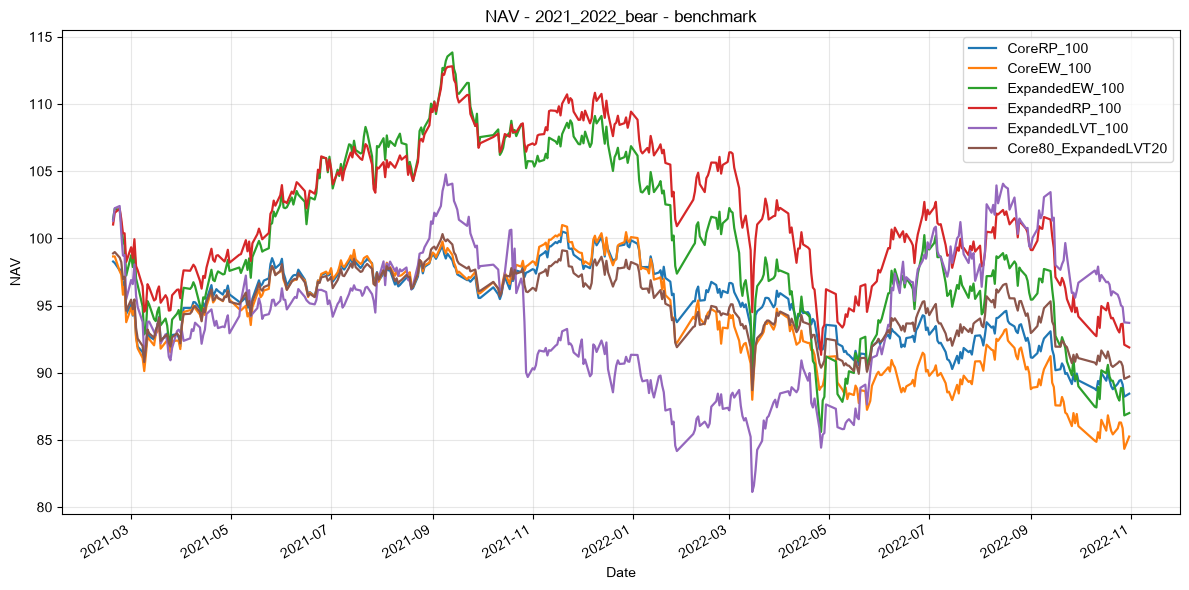

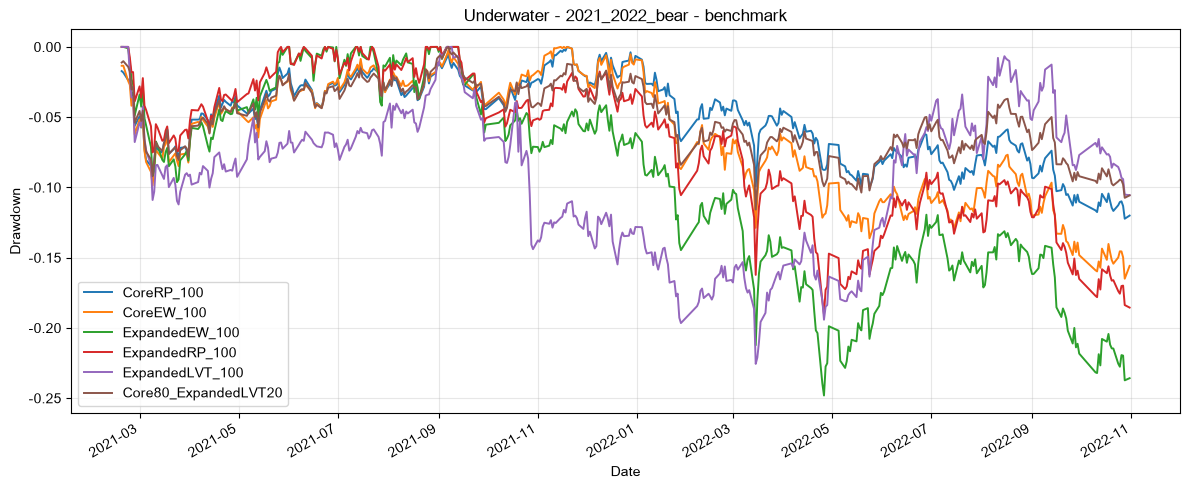

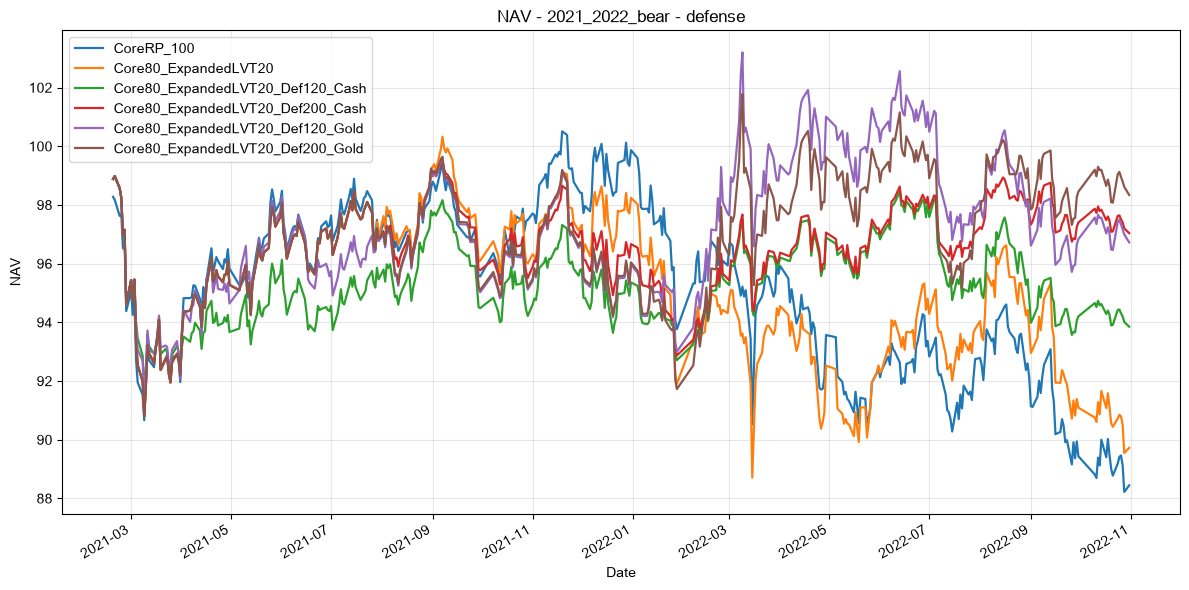

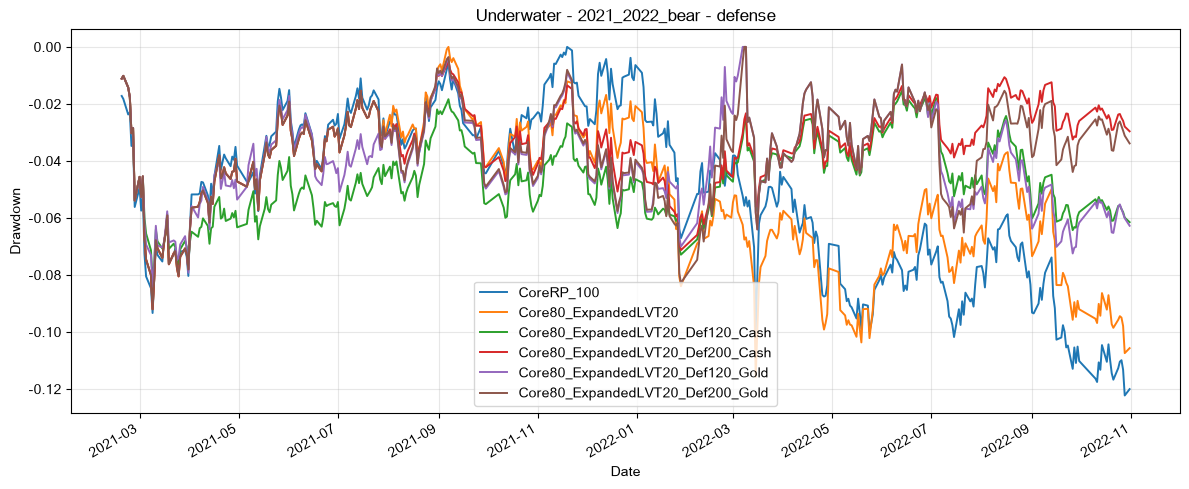

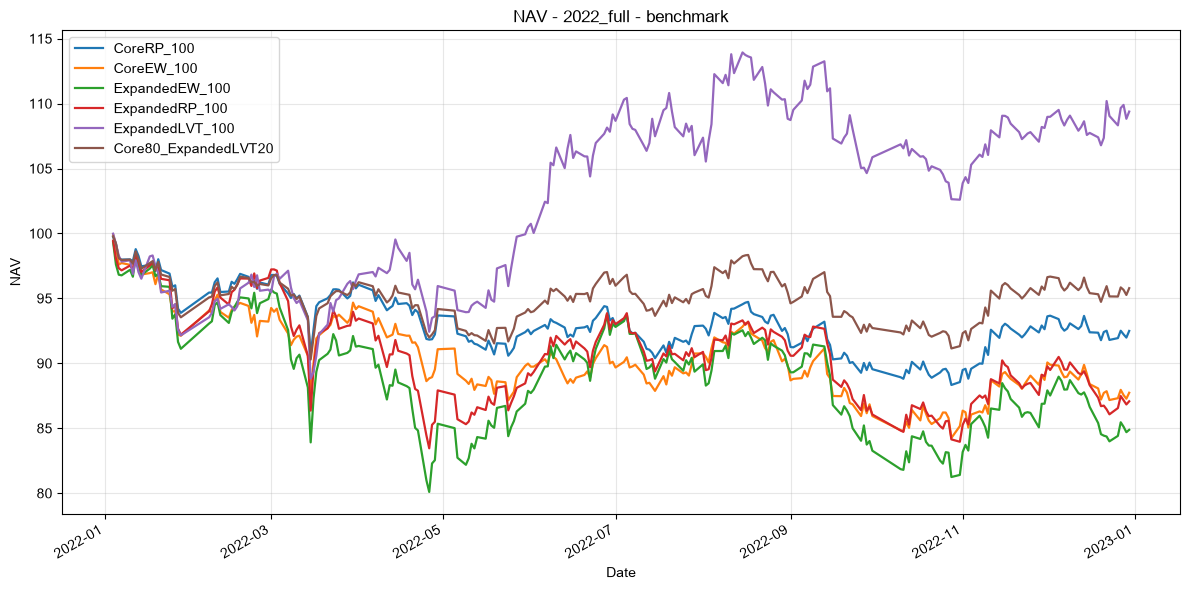

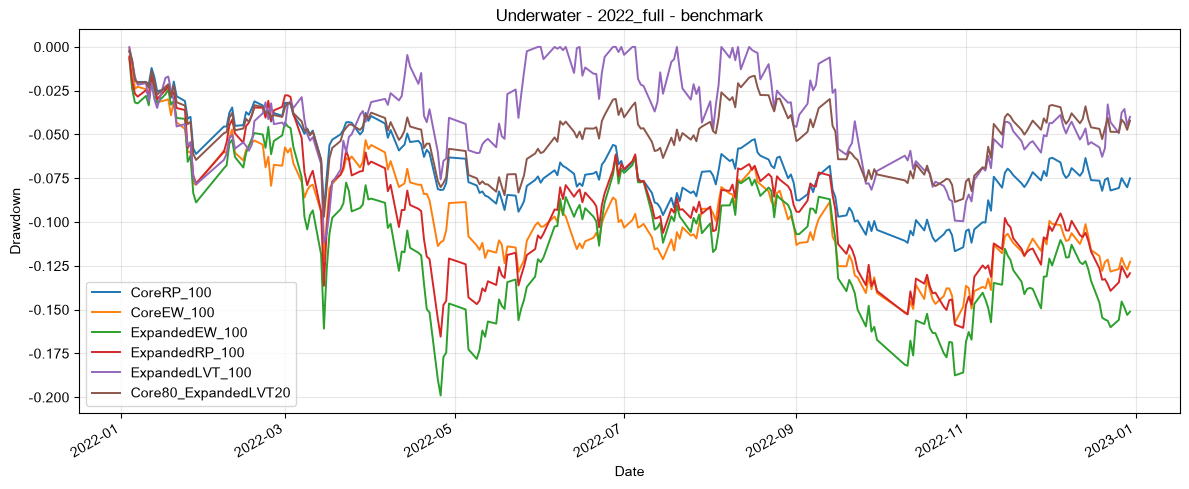

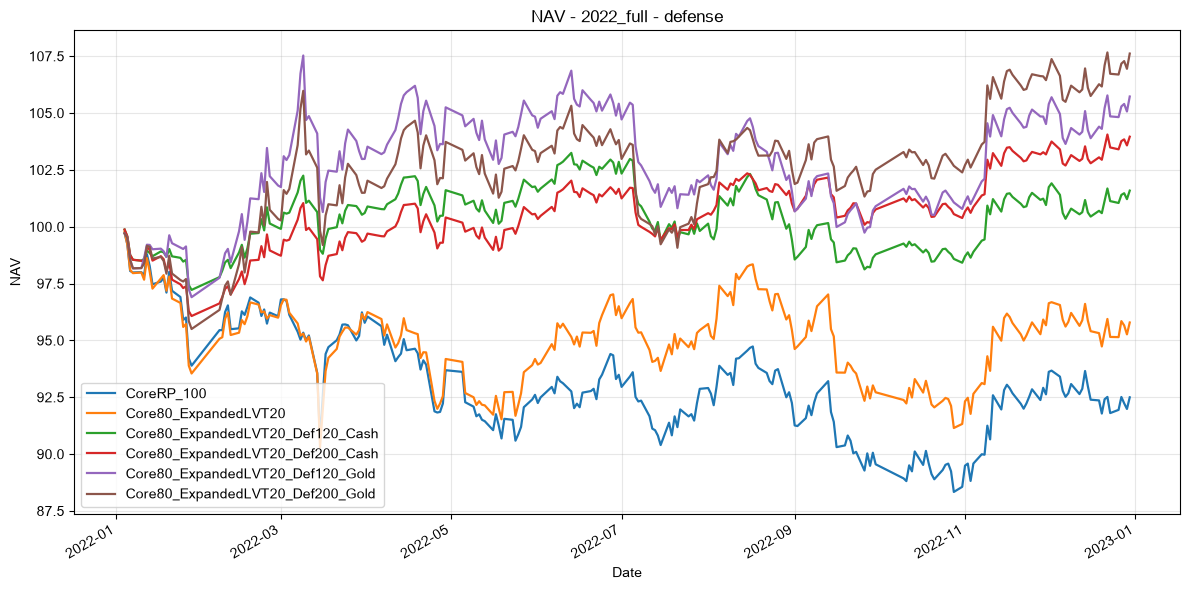

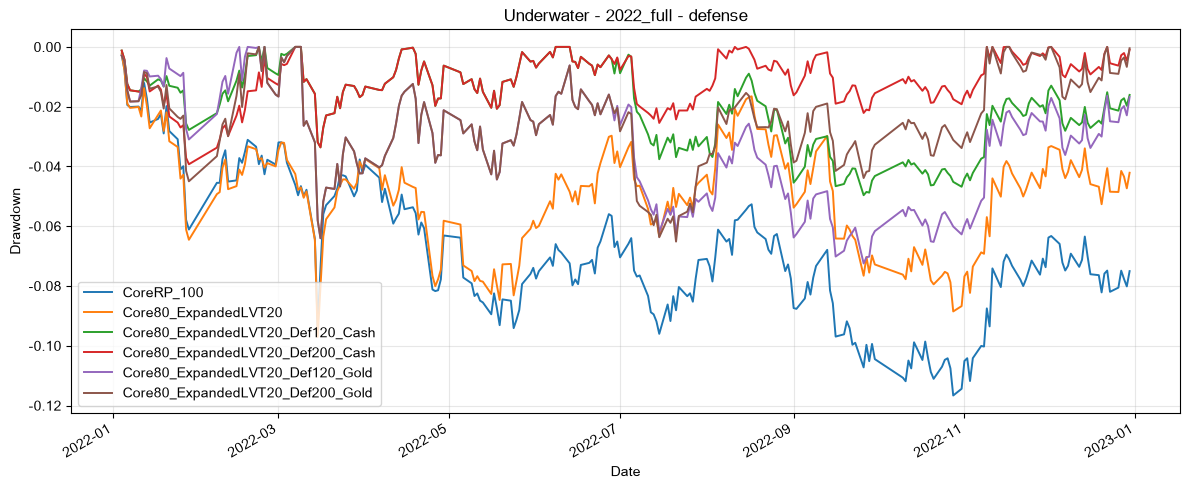

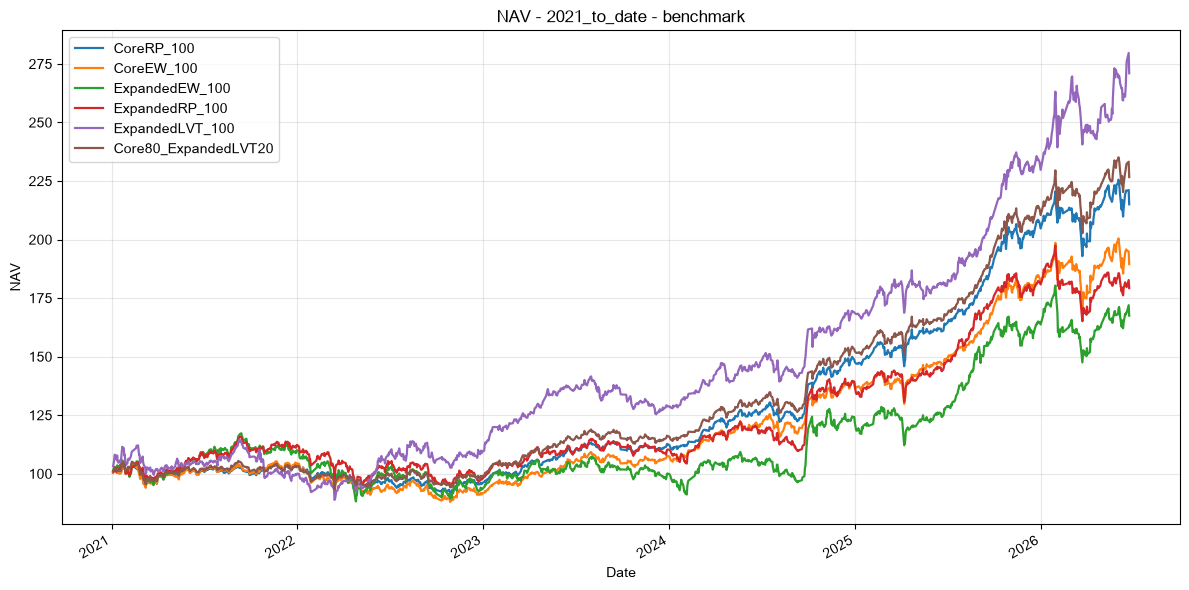

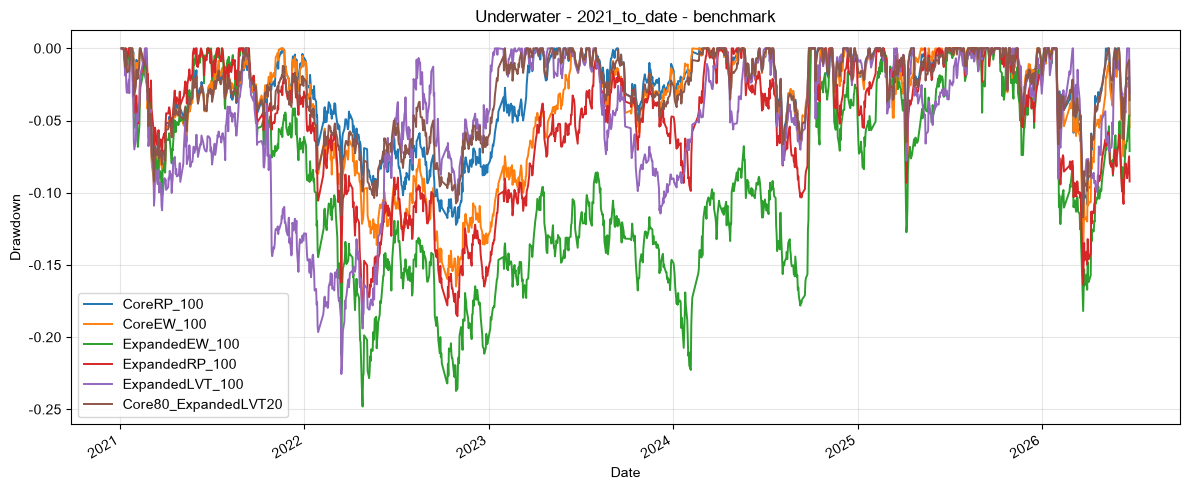

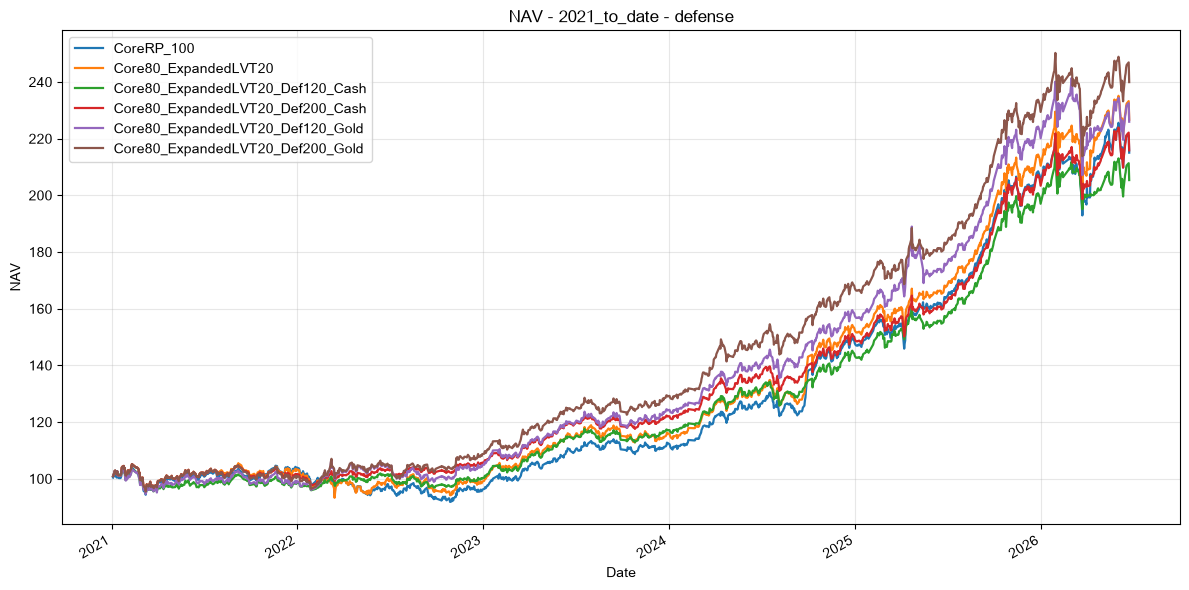

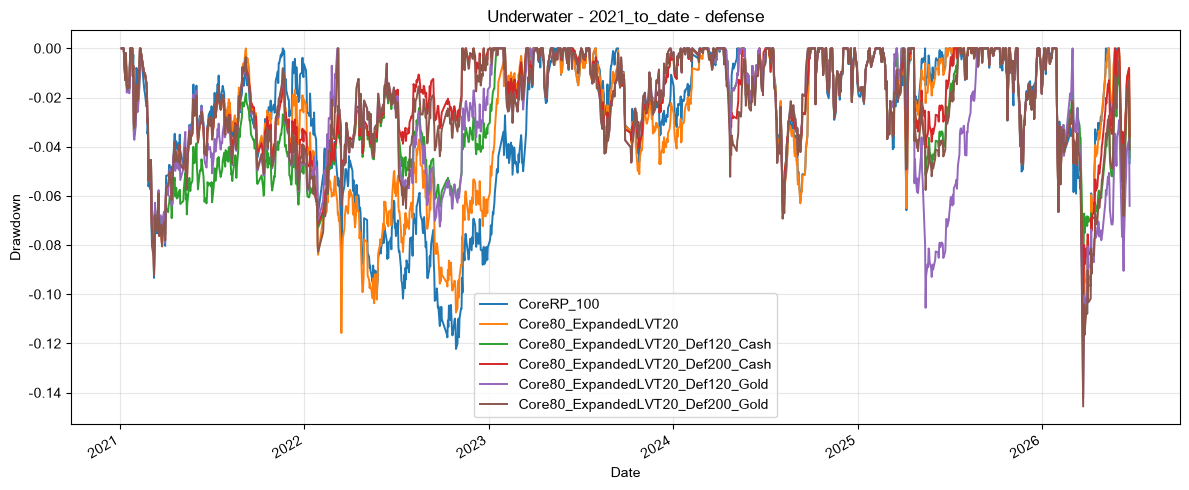

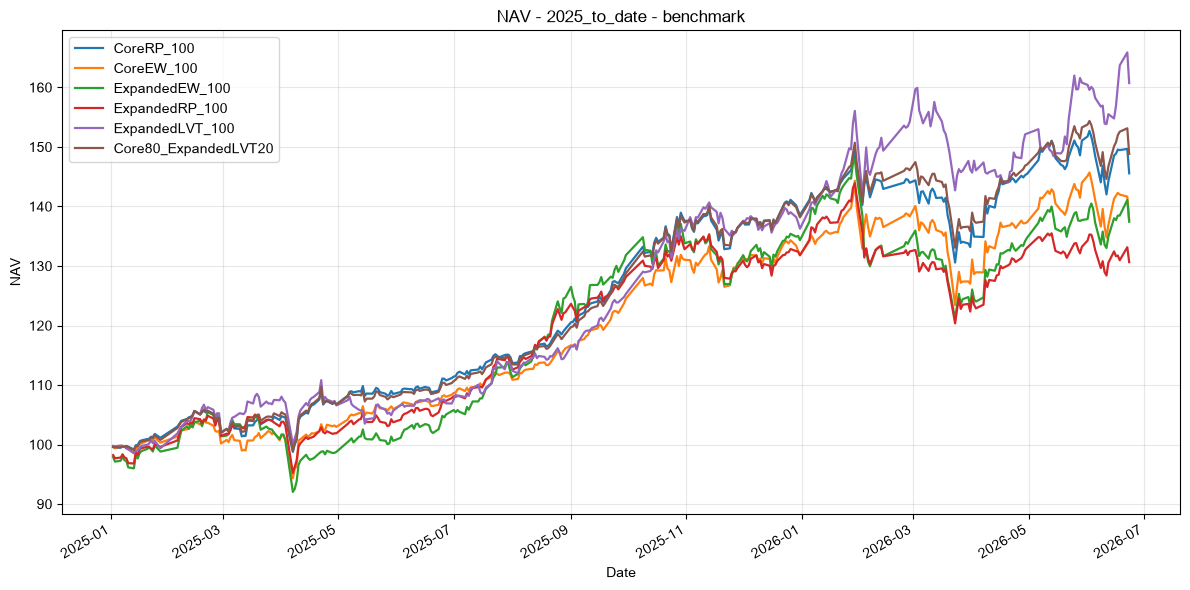

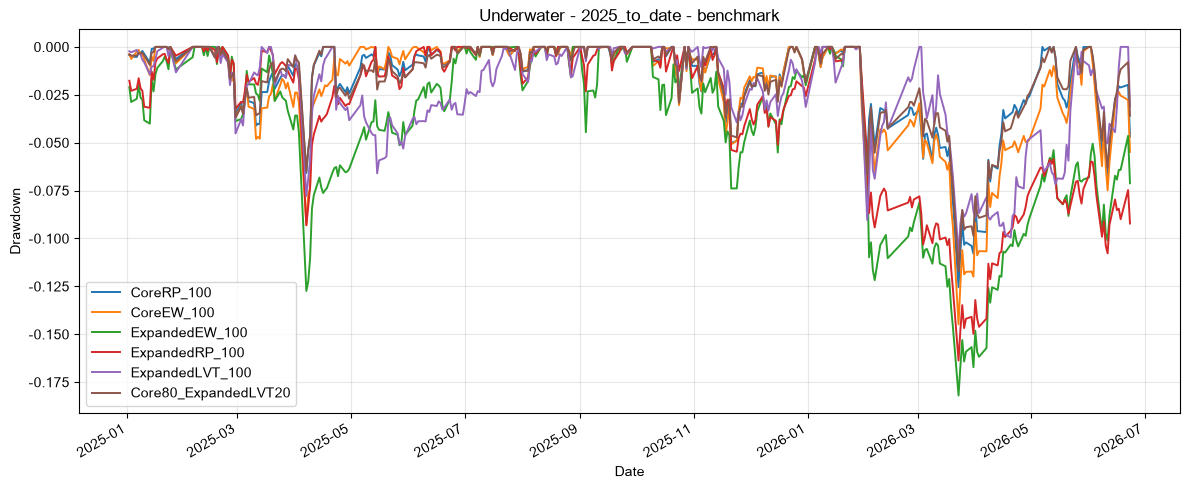

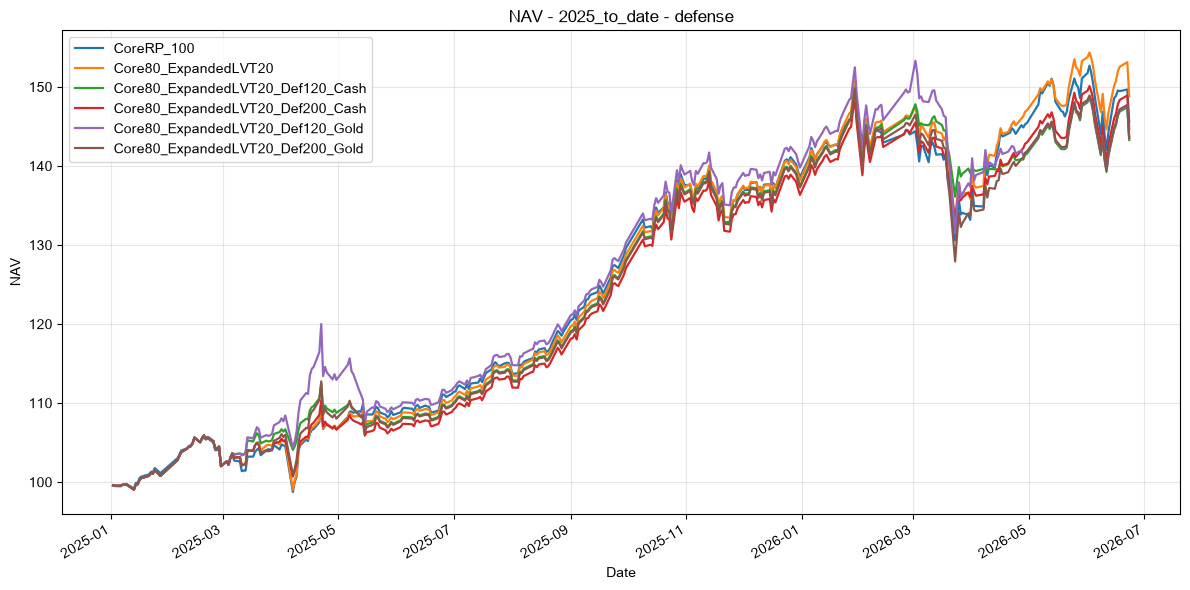

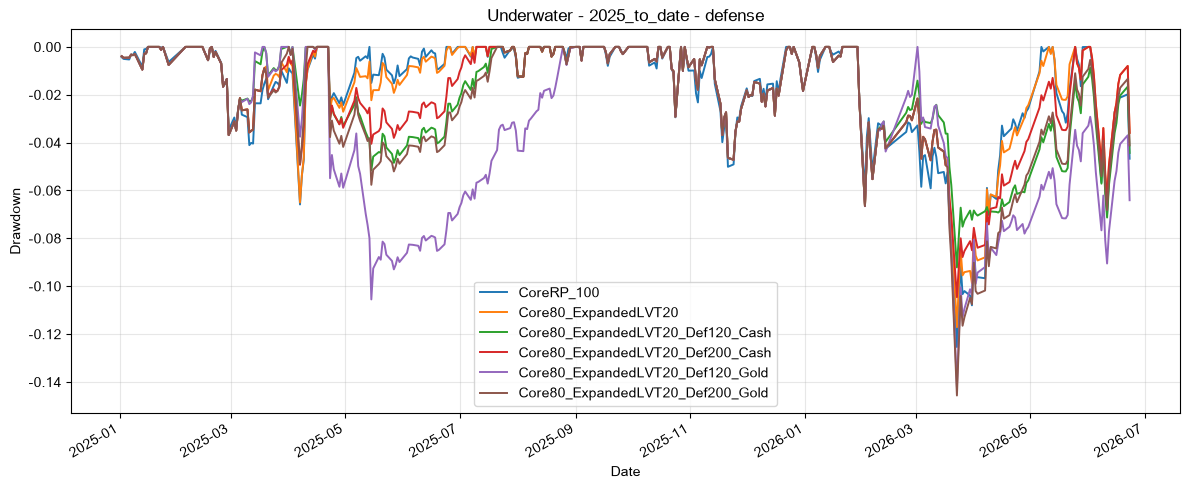

In [8]:
plot_groups = {
    "benchmark": ["CoreRP_100", "CoreEW_100", "ExpandedEW_100", "ExpandedRP_100", "ExpandedLVT_100", "Core80_ExpandedLVT20"],
    "defense": ["CoreRP_100", "Core80_ExpandedLVT20", "Core80_ExpandedLVT20_Def120_Cash", "Core80_ExpandedLVT20_Def200_Cash", "Core80_ExpandedLVT20_Def120_Gold", "Core80_ExpandedLVT20_Def200_Gold"],
}
for window_name in ["2021_2022_bear", "2022_full", "2021_to_date", "2025_to_date"]:
    for group_name, plot_strategies in plot_groups.items():
        nav_df = nav_tables[window_name][plot_strategies]
        uw_df = underwater_tables[window_name][plot_strategies]
        fig, ax = plt.subplots(figsize=(12, 6))
        nav_df.plot(ax=ax, linewidth=1.6)
        ax.set_title(f"NAV - {window_name} - {group_name}")
        ax.set_ylabel("NAV")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f"nav_{window_name}_{group_name}.png", dpi=160)
        plt.show()

        fig, ax = plt.subplots(figsize=(12, 5))
        uw_df.plot(ax=ax, linewidth=1.4)
        ax.set_title(f"Underwater - {window_name} - {group_name}")
        ax.set_ylabel("Drawdown")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f"underwater_{window_name}_{group_name}.png", dpi=160)
        plt.show()

## Research Summary

In [9]:
rs = []
for window in ["2021_2022_bear", "2022_full", "2021_to_date", "2025_to_date"]:
    s = summary_tables[window]
    for strategy in ["CoreRP_100", "ExpandedEW_100", "ExpandedRP_100", "ExpandedLVT_100", "Core80_ExpandedLVT20", "Core80_ExpandedLVT20_Def120_Cash", "Core80_ExpandedLVT20_Def120_Gold", "Core80_ExpandedLVT20_Def200_Cash", "Core80_ExpandedLVT20_Def200_Gold"]:
        rs.append({
            "window": window,
            "strategy": strategy,
            "return": s.loc[strategy, "累计收益"],
            "max_dd": s.loc[strategy, "最大回撤"],
            "sharpe": s.loc[strategy, "夏普"],
            "calmar": s.loc[strategy, "卡玛"],
            "days_below_10pct": s.loc[strategy, "超过-10%天数"],
            "avg_cash": s.loc[strategy, "平均现金"],
        })
research_summary = pd.DataFrame(rs)
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary.round(4))

,window,strategy,return,max_dd,sharpe,calmar,days_below_10pct,avg_cash
0,2021_2022_bear,CoreRP_100,-0.1155,-0.1223,-0.6796,-0.5904,26,0.0000
1,2021_2022_bear,ExpandedEW_100,-0.1300,-0.2480,-0.4657,-0.3283,183,0.0000
2,2021_2022_bear,ExpandedRP_100,-0.0811,-0.1904,-0.3421,-0.2643,137,0.0000
3,2021_2022_bear,ExpandedLVT_100,-0.0629,-0.2256,-0.2235,-0.1722,156,0.0000
4,2021_2022_bear,Core80_ExpandedLVT20,-0.1028,-0.1158,-0.5923,-0.5531,6,0.0000
5,2021_2022_bear,Core80_ExpandedLVT20_Def120_Cash,-0.0615,-0.0817,-0.4711,-0.4650,0,0.2588
6,2021_2022_bear,Core80_ExpandedLVT20_Def120_Gold,-0.0327,-0.0841,-0.1901,-0.2392,0,0.0000
7,2021_2022_bear,Core80_ExpandedLVT20_Def200_Cash,-0.0296,-0.0920,-0.2173,-0.1975,0,0.2441
8,2021_2022_bear,Core80_ExpandedLVT20_Def200_Gold,-0.0166,-0.0920,-0.0953,-0.1104,0,0.0000
9,2022_full,CoreRP_100,-0.0750,-0.1166,-0.7037,-0.6687,23,0.0000


## Plain-Language Conclusion Placeholder

Read the exported scorecards before writing the Q6 review note.